In [401]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# drop nulls from jobSat

In [402]:
data = pd.read_csv('/content/drive/MyDrive/ML project/train_data.csv')

print(data.shape)
data = data.dropna(subset=['JobSat'])
print(data.shape)

(44191, 156)
(23961, 156)


In [403]:
# AI last 21 columns
ai_last21 = data.loc[:, data.columns.str.startswith("AI")].iloc[:, -21:]

extra_cols = ["ICorPM", "YearsCode", "DevType", "OrgSize","JobSat"]

selected_cols = pd.concat([ai_last21, data[extra_cols]], axis=1)

print(selected_cols.columns, selected_cols.shape)

Index(['AIAgent_Uses', 'AIAgentImpactSomewhat agree', 'AIAgentImpactNeutral',
       'AIAgentImpactSomewhat disagree', 'AIAgentImpactStrongly agree',
       'AIAgentImpactStrongly disagree', 'AIAgentChallengesNeutral',
       'AIAgentChallengesSomewhat disagree', 'AIAgentChallengesStrongly agree',
       'AIAgentChallengesSomewhat agree', 'AIAgentChallengesStrongly disagree',
       'AIAgentKnowledge', 'AIAgentKnowWrite', 'AIAgentOrchestration',
       'AIAgentOrchWrite', 'AIAgentObserveSecure', 'AIAgentObsWrite',
       'AIAgentExternal', 'AIAgentExtWrite', 'AIHuman', 'AIOpen', 'ICorPM',
       'YearsCode', 'DevType', 'OrgSize', 'JobSat'],
      dtype='object') (23961, 26)


# Drop columns with null values > 70%

In [404]:
# percentage of missing values for each column
missing_percentages = selected_cols.isnull().sum() / len(selected_cols) * 100

columns_to_drop = missing_percentages[missing_percentages > 70].index.tolist()

print(f"dropped columns: {columns_to_drop}")

print(f"Original columns shape: {selected_cols.shape}")
selected_cols = selected_cols.drop(columns=columns_to_drop)
print(f"New shape after dropping columns: {selected_cols.shape}")


dropped columns: ['AIAgentImpactSomewhat agree', 'AIAgentImpactNeutral', 'AIAgentImpactSomewhat disagree', 'AIAgentImpactStrongly agree', 'AIAgentImpactStrongly disagree', 'AIAgentChallengesStrongly disagree', 'AIAgentKnowledge', 'AIAgentKnowWrite', 'AIAgentOrchestration', 'AIAgentOrchWrite', 'AIAgentObserveSecure', 'AIAgentObsWrite', 'AIAgentExternal', 'AIAgentExtWrite']
Original columns shape: (23961, 26)
New shape after dropping columns: (23961, 12)


In [405]:
for col in selected_cols.columns:
    print(f"\n--- Column: {col} ---")
    display(selected_cols[col].astype(str).value_counts())
    print("-"*100)


--- Column: AIAgent_Uses ---


,count
AIAgent_Uses,
nan,15457
Software engineering,4613
Software engineering;Data and analytics,484
Software engineering;IT operations,324
Software engineering;Business process automation,224
...,...
Software engineering;Business process automation;Decision intelligence;IT operations;Data and analytics;Customer service support;Other Industry purpose (write in):,1
Software engineering;Business process automation;Data and analytics;Marketing;Robotics,1
Software engineering;Decision intelligence;IT operations;Data and analytics;Customer service support;Marketing;Cybersecurity,1


----------------------------------------------------------------------------------------------------

--- Column: AIAgentChallengesNeutral ---


,count
AIAgentChallengesNeutral,
nan,9742
Integrating AI agents with my existing tools and workflows can be difficult.,1666
My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1290
The cost of using certain AI agent platforms is a barrier.,1200
It takes significant time and effort to learn how to use AI agents effectively.,1194
...,...
I am concerned about the accuracy of the information provided by AI agents.;I have concerns about the security and privacy of data when using AI agents.;Write in the most significant challenge if not listed above:,1
I am concerned about the accuracy of the information provided by AI agents.;Integrating AI agents with my existing tools and workflows can be difficult.;I have concerns about the security and privacy of data when using AI agents.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms;Write in the most significant challenge if not listed above:,1
I am concerned about the accuracy of the information provided by AI agents.;Integrating AI agents with my existing tools and workflows can be difficult.;I have concerns about the security and privacy of data when using AI agents.;Write in the most significant challenge if not listed above:,1


----------------------------------------------------------------------------------------------------

--- Column: AIAgentChallengesSomewhat disagree ---


,count
AIAgentChallengesSomewhat disagree,
nan,15537
My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1806
It takes significant time and effort to learn how to use AI agents effectively.,1501
Integrating AI agents with my existing tools and workflows can be difficult.,962
The cost of using certain AI agent platforms is a barrier.,753
...,...
I am concerned about the accuracy of the information provided by AI agents.;It takes significant time and effort to learn how to use AI agents effectively.;The cost of using certain AI agent platforms is a barrier.;I have concerns about the security and privacy of data when using AI agents.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1
I am concerned about the accuracy of the information provided by AI agents.;Integrating AI agents with my existing tools and workflows can be difficult.;It takes significant time and effort to learn how to use AI agents effectively.;I have concerns about the security and privacy of data when using AI agents.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1
Integrating AI agents with my existing tools and workflows can be difficult.;It takes significant time and effort to learn how to use AI agents effectively.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms;Write in the most significant challenge if not listed above:,1


... (15 outputs left out)

,count
OrgSize,
20 to 99 employees,4297
100 to 499 employees,3848
Less than 20 employees,3497
nan,3338
"10,000 or more employees",2924
"1,000 to 4,999 employees",2462
500 to 999 employees,1474
"5,000 to 9,999 employees",934
"Just me - I am a freelancer, sole proprietor, etc.",786


----------------------------------------------------------------------------------------------------

--- Column: JobSat ---


,count
JobSat,
8.0,6287
7.0,5009
9.0,3249
6.0,2890
10.0,2613
5.0,1696
3.0,734
4.0,730
2.0,392


----------------------------------------------------------------------------------------------------


In [406]:
    # 1-MultiChoice cols=
    #'AIAgent_Uses','AIAgentChallengesNeutral','AIAgentChallengesSomewhat disagree','AIAgentChallengesStrongly agree','AIAgentChallengesSomewhat agree','AIHuman'

    # 2-openEnded clos =
    #'AIOpen'

    # 3-cat_cols =
    # 'ICorPM','DevType','OrgSize'

    # 4-num_cols = 'YearsCode'

# AIagentChallenges Columns

In [407]:
#mapping for AIagentChallenges cols values
agree_score = {
    'AIAgentChallengesStrongly disagree': 1,
    'AIAgentChallengesSomewhat disagree': 2,
    'AIAgentChallengesNeutral': 3,
    'AIAgentChallengesSomewhat agree': 4,
    'AIAgentChallengesStrongly agree': 5
}

#process one row
def process_row(row):
    newRow = {}

    for col, score in agree_score.items():
        value = row.get(col)

        if pd.isna(value):
            continue


        challenges = [c.strip() for c in str(value).split(";") if c.strip()]  # Split by ;

        for challenge in challenges:

            newRow[challenge] = max(
                newRow.get(challenge, 0),
                score
            )

    return newRow


processed = selected_cols.apply(process_row, axis=1)

final_df = pd.DataFrame(processed.tolist())

In [408]:
#drop old columns and add the new ones
AIAgentChallenges_cols = [
    'AIAgentChallengesStrongly disagree',
    'AIAgentChallengesSomewhat disagree',
    'AIAgentChallengesNeutral',
    'AIAgentChallengesSomewhat agree',
    'AIAgentChallengesStrongly agree'
]
selected_cols = selected_cols.reset_index(drop=True)
final_df = final_df.reset_index(drop=True)
selected_cols = selected_cols.drop(columns=AIAgentChallenges_cols, errors='ignore')
selected_cols = pd.concat([selected_cols, final_df], axis=1)

In [409]:
#handlling missing values
AIAgentChallenges_cols = [
    "Integrating AI agents with my existing tools and workflows can be difficult.",
    "My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms",
    "I am concerned about the accuracy of the information provided by AI agents.",
    "It takes significant time and effort to learn how to use AI agents effectively.",
    "The cost of using certain AI agent platforms is a barrier.",
    "I have concerns about the security and privacy of data when using AI agents."
]
selected_cols[AIAgentChallenges_cols] = selected_cols[AIAgentChallenges_cols].fillna(3)  # fill nulls with neutral

In [410]:
#"Write in the most significant challenge if not listed above:" cloumn is 90% NULL
selected_cols = selected_cols.drop(columns=[
    "Write in the most significant challenge if not listed above:"
], errors='ignore')

# Spearman corr for AIAgentChallenges

In [411]:
target = "JobSat"

results = []

for col in AIAgentChallenges_cols:

    x = selected_cols[col]
    y = selected_cols[target]

    # Spearman
    spearman_corr, spearman_p = spearmanr(x, y)

    results.append({
        "Feature": col,
        "Spearman_corr": spearman_corr,
        "Spearman_p": spearman_p
    })

corr_df = pd.DataFrame(results)

# sort by absolute Spearman (more robust for Likert)
corr_df = corr_df.sort_values(by="Spearman_corr", key=abs, ascending=False)

print(corr_df)

                                             Feature  Spearman_corr  \
4  The cost of using certain AI agent platforms i...      -0.037198   
0  Integrating AI agents with my existing tools a...      -0.016689   
5  I have concerns about the security and privacy...      -0.015525   
1  My company's IT and/or InfoSec teams have stri...      -0.008416   
2  I am concerned about the accuracy of the infor...      -0.005615   
3  It takes significant time and effort to learn ...       0.002699   

     Spearman_p  
4  8.424004e-09  
0  9.782426e-03  
5  1.625432e-02  
1  1.926913e-01  
2  3.847371e-01  
3  6.761456e-01  


/tmp/ipykernel_31359/1866339111.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Spearman_corr', y='Feature', data=corr_df, palette='viridis')


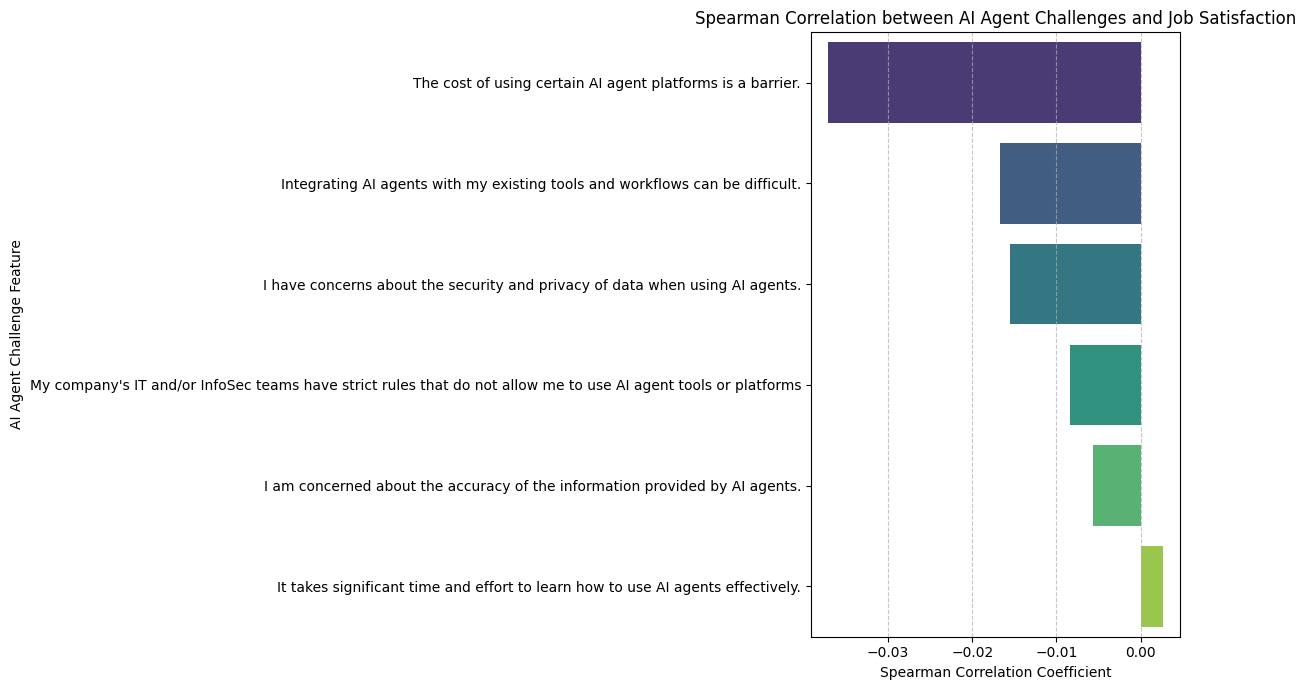

In [412]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot for Spearman correlation coefficients
plt.figure(figsize=(12, 7))
sns.barplot(x='Spearman_corr', y='Feature', data=corr_df, palette='viridis')
plt.title('Spearman Correlation between AI Agent Challenges and Job Satisfaction')
plt.xlabel('Spearman Correlation Coefficient')
plt.ylabel('AI Agent Challenge Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [413]:
selected_cols["AI_Challenges_Score"] = selected_cols[AIAgentChallenges_cols].sum(axis=1)
selected_cols["AI_Challenges_Avg"] = selected_cols[AIAgentChallenges_cols].mean(axis=1)

for col in ["AI_Challenges_Score", "AI_Challenges_Avg"]:
    x = selected_cols[col]
    y = selected_cols[target]

    # Spearman
    spearman_corr, spearman_p = spearmanr(x, y)
    results.append({
        "Feature": col,
        "Spearman_corr": spearman_corr,
        "Spearman_p": spearman_p
    })

corr_df = pd.DataFrame(results)
corr_df = corr_df.sort_values(by="Spearman_corr", key=abs, ascending=False)

print(corr_df)

                                             Feature  Spearman_corr  \
4  The cost of using certain AI agent platforms i...      -0.037198   
6                                AI_Challenges_Score      -0.024808   
7                                  AI_Challenges_Avg      -0.024808   
0  Integrating AI agents with my existing tools a...      -0.016689   
5  I have concerns about the security and privacy...      -0.015525   
1  My company's IT and/or InfoSec teams have stri...      -0.008416   
2  I am concerned about the accuracy of the infor...      -0.005615   
3  It takes significant time and effort to learn ...       0.002699   

     Spearman_p  
4  8.424004e-09  
6  1.227690e-04  
7  1.227690e-04  
0  9.782426e-03  
5  1.625432e-02  
1  1.926913e-01  
2  3.847371e-01  
3  6.761456e-01  


In [414]:
# all values are <0.04 -> Drop

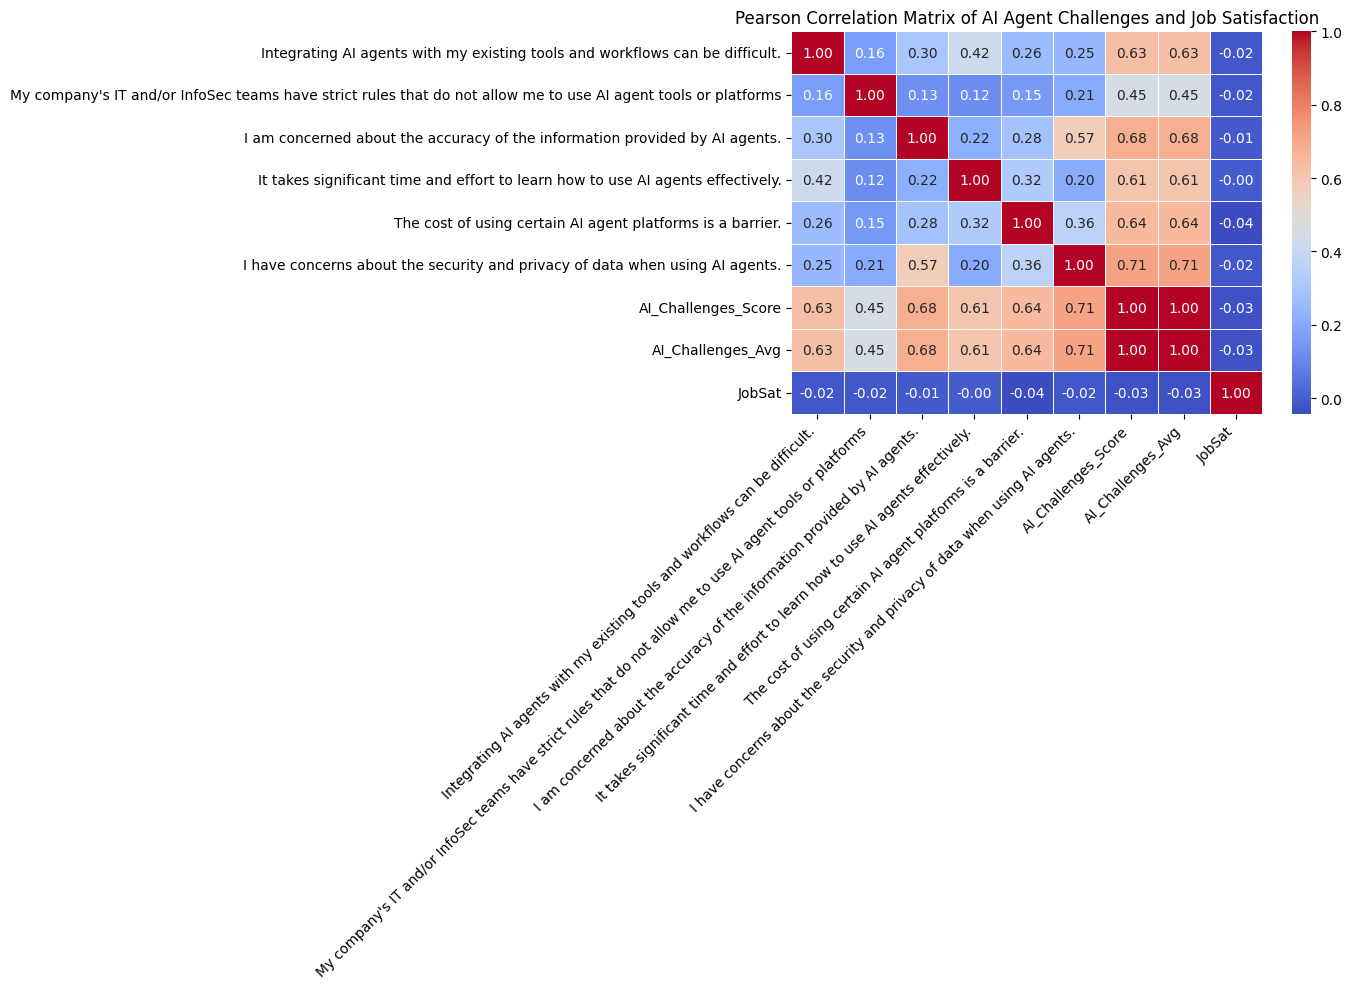

In [415]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the columns for the correlation matrix
# We include AIAgentChallenges_cols, AI_Challenges_Score, AI_Challenges_Avg, and the target JobSat
correlation_features = AIAgentChallenges_cols + ["AI_Challenges_Score", "AI_Challenges_Avg", "JobSat"]

# Subset the DataFrame to include only these columns
corr_data = selected_cols[correlation_features]

# Calculate the Pearson correlation matrix
pearson_corr_matrix = corr_data.corr(method='pearson')

# Plot the heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(pearson_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Pearson Correlation Matrix of AI Agent Challenges and Job Satisfaction')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [416]:
# Identify columns to drop based on absolute Spearman correlation < 0.04
columns_to_drop_by_corr = corr_df[abs(corr_df['Spearman_corr']) < 0.04]['Feature'].tolist()

selected_cols = selected_cols.drop(columns=columns_to_drop_by_corr, errors='ignore')
selected_cols = selected_cols.drop(columns='AI_Challenges_Score', errors='ignore')
selected_cols.columns

Index(['AIAgent_Uses', 'AIHuman', 'AIOpen', 'ICorPM', 'YearsCode', 'DevType',
       'OrgSize', 'JobSat'],
      dtype='object')

# AIAgent_Uses & AIHuman Columns

In [417]:
# for col in selected_cols.columns:
#     print(f"\n--- Column: {col} ---")
#     # Convert to string to handle mixed types if any, and then get value counts
#     display(selected_cols[col].astype(str).value_counts())
#     print("----------------------")

In [418]:
selected_cols['AIAgent_Uses_Count'] = (
    selected_cols['AIAgent_Uses']
    .fillna('')
    .apply(lambda x: 0 if x == '' else x.count(';') + 1)
)
selected_cols=selected_cols.drop(columns='AIAgent_Uses')

In [419]:
selected_cols['AIAgent_Uses_Count'].head()

,AIAgent_Uses_Count
0,1
1,0
2,1
3,1
4,4


# Spearman Corr

In [420]:
from scipy.stats import spearmanr

corr, p = spearmanr(selected_cols['AIAgent_Uses_Count'], selected_cols['JobSat'])
print(corr, p) #0.046233730705787034 8.059929191472863e-13

0.046233730705787034 8.059929191472863e-13


In [421]:
selected_cols.columns

Index(['AIHuman', 'AIOpen', 'ICorPM', 'YearsCode', 'DevType', 'OrgSize',
       'JobSat', 'AIAgent_Uses_Count'],
      dtype='object')

## AIHuman Column

In [422]:
selected_cols['AIHuman'] = selected_cols['AIHuman'].fillna('None') #fill nulls to encode
AIHuman_encoded = selected_cols["AIHuman"].str.get_dummies(sep=";") #split values and apply encoding

AIHuman_encoded.columns = [ #rename colums to "AIHuman_{value}"
    "AIHuman_" + col.strip().replace(" ", "_")
    for col in AIHuman_encoded.columns
]

In [423]:
#cncatinate the result with other columns and drop old one
selected_cols = selected_cols.reset_index(drop=True)
AIHuman_encoded = AIHuman_encoded.reset_index(drop=True)

selected_cols = pd.concat([selected_cols, AIHuman_encoded], axis=1)
selected_cols = selected_cols.drop(columns=["AIHuman"], errors='ignore')

In [424]:
# count number of users using each feature
counts = AIHuman_encoded.sum()
counts.sort_values(ascending=False)

,0
AIHuman_When_I_don’t_trust_AI’s_answers,14935
AIHuman_When_I_have_ethical_or_security_concerns_about_code,12208
AIHuman_When_I_want_to_fully_understand_something,11968
AIHuman_When_I_want_to_learn_best_practices,11400
AIHuman_When_I’m_stuck_and_can’t_explain_the_problem,10706
AIHuman_When_I_need_help_fixing_complex_or_unfamiliar_code,9884
AIHuman_When_I_want_to_compare_different_solutions,8702
AIHuman_When_I_need_quick_help_troubleshooting,5479
AIHuman_None,4352
AIHuman_Other_(please_specify):,1194


In [425]:
from sklearn.feature_selection import mutual_info_regression

AIHuman_cols = [
    'AIHuman_When_I_don’t_trust_AI’s_answers',
    'AIHuman_When_I_have_ethical_or_security_concerns_about_code',
    'AIHuman_When_I_want_to_fully_understand_something',
    'AIHuman_When_I_want_to_learn_best_practices',
    'AIHuman_When_I’m_stuck_and_can’t_explain_the_problem',
    'AIHuman_When_I_need_help_fixing_complex_or_unfamiliar_code',
    'AIHuman_When_I_want_to_compare_different_solutions',
    'AIHuman_When_I_need_quick_help_troubleshooting',
    'AIHuman_None',
    'AIHuman_Other_(please_specify):',
    'AIHuman_I_don’t_think_I’ll_need_help_from_people_anymore'
]

mi = mutual_info_regression(selected_cols[AIHuman_cols], selected_cols['JobSat'],random_state=42)

for f, score in zip(AIHuman_cols, mi):
    print(f"{f}: {score}")

AIHuman_When_I_don’t_trust_AI’s_answers: 0.005751781448512183
AIHuman_When_I_have_ethical_or_security_concerns_about_code: 0.0020304865988887144
AIHuman_When_I_want_to_fully_understand_something: 0.0
AIHuman_When_I_want_to_learn_best_practices: 0.0
AIHuman_When_I’m_stuck_and_can’t_explain_the_problem: 0.0032107648237618136
AIHuman_When_I_need_help_fixing_complex_or_unfamiliar_code: 0.0
AIHuman_When_I_want_to_compare_different_solutions: 0.0
AIHuman_When_I_need_quick_help_troubleshooting: 0.0
AIHuman_None: 0.0006012393809307071
AIHuman_Other_(please_specify):: 0.007772606611787136
AIHuman_I_don’t_think_I’ll_need_help_from_people_anymore: 0.0


In [ ]:
#grouping AIHuman cols
selected_cols['AIHuman_Count'] = selected_cols[AIHuman_cols].sum(axis=1)

learning_cols = [
    'AIHuman_When_I_want_to_fully_understand_something',
    'AIHuman_When_I_want_to_learn_best_practices'
]
selected_cols['AIHuman_Learning'] = selected_cols[learning_cols].sum(axis=1)


trust_cols = [
    'AIHuman_When_I_don’t_trust_AI’s_answers',
    'AIHuman_When_I_have_ethical_or_security_concerns_about_code'
]
selected_cols['AIHuman_Trust'] = selected_cols[trust_cols].sum(axis=1)


help_cols = [
    'AIHuman_When_I_need_help_fixing_complex_or_unfamiliar_code',
    'AIHuman_When_I_need_quick_help_troubleshooting',
    'AIHuman_When_I’m_stuck_and_can’t_explain_the_problem'
]
selected_cols['AIHuman_Help'] = selected_cols[help_cols].sum(axis=1)


selected_cols['AIHuman_Exploration'] = selected_cols[
    'AIHuman_When_I_want_to_compare_different_solutions'
]

selected_cols = selected_cols.drop(columns=AIHuman_cols)



In [427]:
from sklearn.feature_selection import mutual_info_regression

features = [
    'AIHuman_Count',
    'AIHuman_Learning',
    'AIHuman_Trust',
    'AIHuman_Help',
    'AIHuman_Exploration'
]

mi = mutual_info_regression(selected_cols[features], selected_cols['JobSat'],random_state=42)

for f, score in zip(features, mi):
    print(f"{f}: {score}")

AIHuman_Count: 0.0
AIHuman_Learning: 0.003723907079964839
AIHuman_Trust: 0.007956711101471114
AIHuman_Help: 0.0023874770100267284
AIHuman_Exploration: 0.0


In [428]:
#MI of all clos < 0.007 except AIHuman_Trust
selected_cols = selected_cols.drop(columns=['AIHuman_Count','AIHuman_Learning','AIHuman_Help','AIHuman_Exploration'])

In [429]:
selected_cols.columns

Index(['AIOpen', 'ICorPM', 'YearsCode', 'DevType', 'OrgSize', 'JobSat',
       'AIAgent_Uses_Count', 'AIHuman_Trust'],
      dtype='object')

# YearsCode

In [430]:
#handelling missing values
selected_cols["YearsCode"] = selected_cols["YearsCode"].fillna(selected_cols["YearsCode"].median())

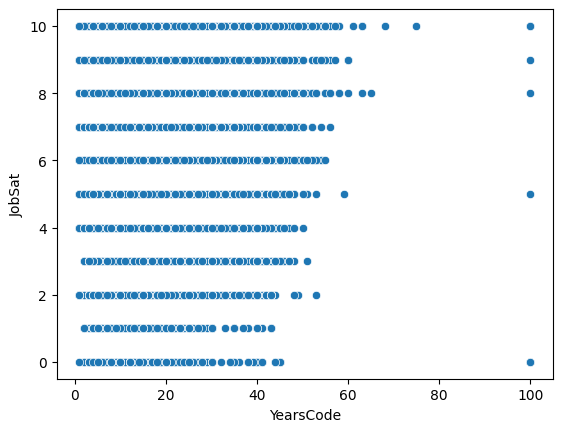

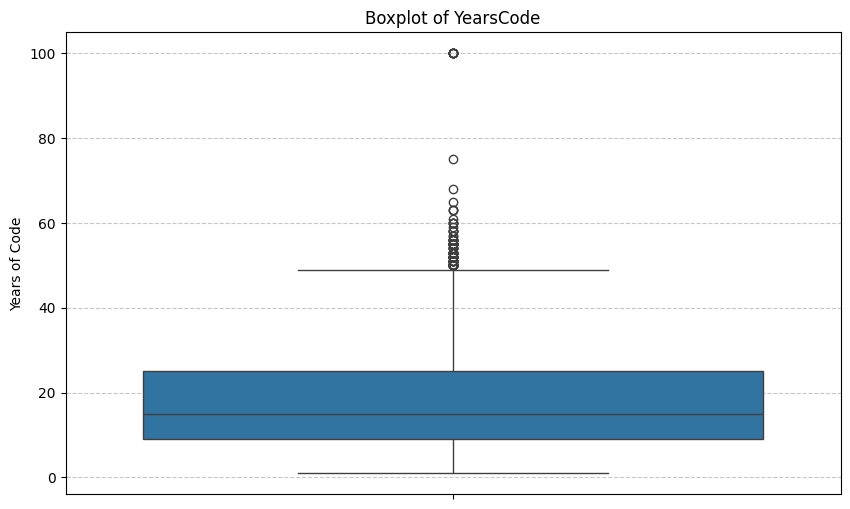

In [431]:
sns.scatterplot(x='YearsCode', y='JobSat', data=selected_cols)

plt.figure(figsize=(10, 6))
sns.boxplot(y=selected_cols['YearsCode'])
plt.title('Boxplot of YearsCode')
plt.ylabel('Years of Code')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [432]:
x = selected_cols['YearsCode']
y = selected_cols['JobSat']

# Spearman
spearman_corr, spearman_p = spearmanr(x, y)
print("Spearman:", spearman_corr, spearman_p)

Spearman: 0.1056336895240403 2.027921793241221e-60


# OrgSize

In [433]:
#handelling missing values
selected_cols["OrgSize"] = selected_cols["OrgSize"].fillna("Unknown")

#Ordinal encoding
org_map = {
    "Just me - I am a freelancer, sole proprietor, etc.": 0,
    "Less than 20 employees": 1,
    "20 to 99 employees": 2,
    "100 to 499 employees": 3,
    "500 to 999 employees": 4,
    "1,000 to 4,999 employees": 5,
    "5,000 to 9,999 employees": 6,
    "10,000 or more employees": 7,
    "Unknown": 8,
    "I don’t know": 8
}

selected_cols["OrgSize"] = selected_cols["OrgSize"].map(org_map)

In [434]:
selected_cols["OrgSize"].value_counts()

,count
OrgSize,
2,4297
3,3848
8,3739
1,3497
7,2924
5,2462
4,1474
6,934
0,786


In [435]:
df = selected_cols[selected_cols['OrgSize'] != -1]

df.groupby('OrgSize')['JobSat'].mean().sort_index()

,JobSat
OrgSize,
0,7.581425
1,7.334858
2,7.232488
3,7.211538
4,7.181140
5,7.134444
6,7.230193
7,7.110465
8,7.079968


In [436]:
corr, p = spearmanr(selected_cols['OrgSize'], selected_cols['JobSat'])
print(corr, p)

-0.03317117323023169 2.809098654342723e-07


In [437]:
#weak corr -> Drop
selected_cols=selected_cols.drop(columns=['OrgSize'])

# DevType

In [438]:
# selected_cols["DevType"].value_counts()

In [439]:
# selected_cols.groupby('DevType')['JobSat'].mean().sort_index()

In [440]:
selected_cols.groupby('DevType')['JobSat'].agg(['mean', 'count']) \
  .sort_values('mean', ascending=False)

,mean,count
DevType,,
"Founder, technology or otherwise",8.371560,218
"Senior executive (C-suite, VP, etc.)",8.095436,241
Product manager,8.054054,37
Financial analyst or engineer,7.650000,20
Cybersecurity or InfoSec professional,7.630000,100
"Architect, software or solutions",7.553179,1683
Applied scientist,7.546392,97
Academic researcher,7.428000,250
Engineering manager,7.402256,532


In [441]:
dev_mean = selected_cols.groupby('DevType')['JobSat'].mean()

selected_cols['DevType_encoded'] = selected_cols['DevType'].map(dev_mean)

In [443]:
mutual_info_regression(selected_cols[['DevType_encoded']], selected_cols['JobSat'],random_state=42)

array([0.01356383])

In [444]:
spearmanr(selected_cols['DevType_encoded'], selected_cols['JobSat'])

SignificanceResult(statistic=np.float64(0.09278906236575085), pvalue=np.float64(5.688956943870719e-47))

In [445]:
def group_dev_type(dev_type):
    """Maps a specific developer type to a broader engineering discipline."""
    if pd.isna(dev_type):
        return 'Unknown'
    dev_type = str(dev_type)
    if any(keyword in dev_type for keyword in ['back-end', 'front-end', 'full-stack', 'mobile', 'desktop', 'embedded', 'game', 'Architect', 'QA']):
        return 'Software Engineering'
    elif any(keyword in dev_type for keyword in ['Data scientist', 'Data engineer', 'AI/ML engineer', 'AI apps', 'Data or business analyst', 'Applied scientist']):
        return 'Data & AI'
    elif any(keyword in dev_type for keyword in ['Cloud', 'DevOps', 'System administrator', 'Database', 'Cybersecurity', 'Support']):
        return 'Infrastructure & Ops'
    elif any(keyword in dev_type for keyword in ['manager', 'executive', 'Founder', 'VP']):
        return 'Leadership & Product'
    else:
        return 'Other / Specialized'

def apply_dev_grouping(data):
    df_temp = data.copy()
    df_temp['DevType_Grouped'] = df_temp['DevType'].apply(group_dev_type)
    return df_temp

selected_cols = apply_dev_grouping(selected_cols)
selected_cols.groupby('DevType_Grouped')['JobSat'].mean().sort_index()

le = LabelEncoder()
selected_cols['DevType_Grouped'] = le.fit_transform(selected_cols['DevType_Grouped'])
dict(zip(le.classes_, le.transform(le.classes_)))

f_classif(selected_cols[['DevType_Grouped']], selected_cols['JobSat'])


(array([3.6127187]), array([8.07174245e-05]))

In [446]:
mutual_info_regression(selected_cols[['DevType_Grouped']], selected_cols['JobSat'],random_state=42)

array([0.00820392])

In [447]:
#Mean encoding -> (highest F-statistic and highest mutual information) (each category encoded to the mean of JobSat)
#Label encoding with grouping -> performs worse (producing lower F and lower MI)
selected_cols = selected_cols.drop(columns=['DevType','DevType_Grouped'])

# ICorPM


In [448]:
#handelling missing values
selected_cols["ICorPM"] = selected_cols["ICorPM"].fillna("Unknown")

selected_cols.groupby('ICorPM')['JobSat'].mean().sort_index()

,JobSat
ICorPM,
Individual contributor,7.172646
People manager,7.546338
Unknown,7.103145


In [449]:
le = LabelEncoder()
selected_cols['ICorPM'] = le.fit_transform(selected_cols['ICorPM'])

In [451]:
mutual_info_regression(selected_cols[['ICorPM']], selected_cols['JobSat'],random_state=42)

array([0.00605487])

# AIOpen

In [453]:
selected_cols=selected_cols.drop(columns='AIOpen') #open ended column will be analyzed by nlp model

# Final selected columns

In [454]:
selected_cols.head()

,ICorPM,YearsCode,JobSat,AIAgent_Uses_Count,AIHuman_Trust,DevType_encoded
0,1,14.0,10.0,1,1,7.238095
1,0,10.0,9.0,0,2,7.038392
2,2,12.0,8.0,1,2,6.953895
3,0,5.0,6.0,1,2,7.038392
4,2,20.0,7.0,4,1,7.038392


In [455]:
selected_cols=selected_cols.drop(columns='JobSat')
selected_cols.columns

Index(['ICorPM', 'YearsCode', 'AIAgent_Uses_Count', 'AIHuman_Trust',
       'DevType_encoded'],
      dtype='object')

correlations :
AIagreement levels (4 cols)-> max=0.037 (Drop)

AIAgent_Count (from AIAgent_Uses) -> 0.046 *

YearsCode -> 0.1 *

OrgSize -> 0.033 (Drop)

DevType -> 0.09 *





MIs:

AIHuman (AIHuman_Trust)-> 0.0079


ICorPM -> 0.006  
